IMPORTEREN

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("../data/etl-synthetic_perined.csv")

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import numpy as np

1.VERKENNING

In [ ]:
print('Aantal rijen en kolommen:')
df.shape

Aantal rijen en kolommen:


(100000, 47)

In [ ]:
df.info()

In [ ]:
df.head()

In [ ]:
print("Aantal dubbele rijen:", df.duplicated().sum())

Aantal dubbele rijen: 0


In [ ]:
df.columns

Index(['ovdr12', 'verantw_zw', 'verantw_bb', 'verantw_eb', 'jaar', 'pc4',
       'provincie', 'gebplaats', 'type_partus', 'beginbaring_detail', 'lft',
       'ses_percentiel', 'par', 'grav', 'gesl', 'geboortegew', 'apgar5',
       'amddd', 'hoftiezer', 'amww', 'whodef', 'amddd1ond', 'ligging',
       'pediater', 'fluxus', 'congenafw1', 'congenafw2', 'congenafw3',
       'congenafw4', 'congenafw5', 'congenafw6', 'congenafw7', 'congenafw8',
       'sterfte', 'stedelijkheid', 'pijnbestrijding2', 'nicuopname',
       'versienummer', 'alcoholgebruik', 'drugsgebruik', 'episiotomie',
       'ruptuur', 'vrouwniveau', 'beginbaring_basis', 'etnic', 'rookgedrag',
       'sectio_ia'],
      dtype='str')

In [ ]:
df.dtypes

ovdr12                  int64
verantw_zw              int64
verantw_bb              int64
verantw_eb              int64
jaar                    int64
pc4                   float64
provincie               int64
gebplaats             float64
type_partus           float64
beginbaring_detail    float64
lft                   float64
ses_percentiel        float64
par                   float64
grav                  float64
gesl                  float64
geboortegew           float64
apgar5                float64
amddd                   int64
hoftiezer             float64
amww                    int64
whodef                  int64
amddd1ond             float64
ligging               float64
pediater                int64
fluxus                  int64
congenafw1            float64
congenafw2            float64
congenafw3            float64
congenafw4            float64
congenafw5            float64
congenafw6            float64
congenafw7            float64
congenafw8            float64
sterfte   

Lablels voor sleutelkolommen

In [ ]:
ligging_labels = {
    70028003: "Achterhoofd-voor", 37235006: "Achterhoofd-achter", 249079005: "Kruin",
    21882006: "Aangezicht", 8014007: "Voorhoofd", 49168004: "Volkomen stuit",
    38049006: "Half onvolkomen stuit", 18559007: "Onvolkomen stuit",
}
type_partus_labels = {
    48782003: "Spontaan", 8561000146109: "Vaginale kunstverlossing",
    200148001: "Sectio primair", 200149009: "Sectio secundair", 39406005: "TOP",
}
beginbaring_labels = {1: "Inleiding", 2: "Primaire sectio", 3: "Spontaan", 9: "Onbekend"}
gebplaats_labels = {0: "Thuis", 1: "Geboortecentrum", 2: "Ziekenhuis 1e lijn",
                    3: "Ziekenhuis 2e lijn", 4: "Onderweg", 5: "Onbekend"}

def label(kolom, labels):
    
    return df[kolom].astype("Int64").map(labels)

OBSERVATIE: Deze code zal ik beter in de ETL gebruiken om de transformatie aan te passen en de labels te krigen

2.STATISTIEKEN

In [ ]:
numeriek = ["lft", "par", "grav", "geboortegew", "apgar5", "amddd", "amww",
            "amddd1ond", "hoftiezer", "ses_percentiel"]
categorisch = [k for k in df.columns if k not in numeriek + ["pc4", "jaar"]]

print(len(numeriek), "numerieke kolommen")
print(len(categorisch), "categorische kolommen")

10 numerieke kolommen
35 categorische kolommen


In [ ]:
df[numeriek].describe().round(1)

,lft,par,grav,geboortegew,apgar5,amddd,amww,amddd1ond,hoftiezer,ses_percentiel
count,99705.0,99569.0,99628.0,99883.0,99865.0,100000.0,100000.0,94669.0,99250.0,99206.0
mean,30.9,0.9,2.2,3411.5,9.5,277.2,39.2,73.6,50.1,50.4
std,4.8,1.1,1.3,11691.6,1.0,13.8,2.0,59.1,28.9,29.0
min,10.0,0.0,1.0,0.0,0.0,168.0,24.0,1.0,1.0,1.0
25%,28.0,0.0,1.0,3042.0,9.0,273.0,39.0,32.0,25.0,25.0
50%,31.0,1.0,2.0,3406.0,10.0,279.0,39.0,55.0,50.0,50.0
75%,34.0,1.0,3.0,3749.0,10.0,285.0,40.0,94.0,75.0,76.0
max,59.0,29.0,56.0,3694000.0,10.0,315.0,45.0,304.0,100.0,100.0


Observatie: onmogelijke waarden zoals grav = 56 of gewicht 3694000 zal ik in de ETL als NaN zetten

In [ ]:
df.nunique().sort_values()

congenafw6               0
congenafw1               0
congenafw7               0
congenafw8               0
rookgedrag               0
sectio_ia                0
etnic                    0
whodef                   1
congenafw5               1
vrouwniveau              1
versienummer             1
nicuopname               2
alcoholgebruik           2
fluxus                   2
drugsgebruik             2
verantw_zw               3
verantw_eb               3
gesl                     3
verantw_bb               3
congenafw4               4
episiotomie              4
beginbaring_basis        4
stedelijkheid            5
pediater                 5
type_partus              5
ovdr12                   5
gebplaats                6
pijnbestrijding2         6
congenafw2               6
beginbaring_detail       6
sterfte                  7
congenafw3               7
ruptuur                  8
ligging                  8
par                     10
jaar                    11
apgar5                  11
p

Observatie: Lege kolommen en constante kolommen zal ik verwijderen van de dataset in de ETL

In [ ]:
(df["lft"] < 16).sum()

np.int64(68)

In [ ]:
(df["geboortegew"] == 0).sum()

np.int64(10)

Observatie: Deze 10 waarden zal ik in de ETL als Nan zetten

In [ ]:
df[df["geboortegew"] > 6000]["geboortegew"].value_counts()

geboortegew
3694000.0    1
Name: count, dtype: int64

ik zal dit delen door 1000, was een typefout waarschijnlijk.

In [ ]:
df["ligging"].nunique()

8

In [ ]:
df["ligging"].unique()

array([7.00280030e+07, 2.49079005e+08, 3.72350060e+07, 1.85590070e+07,
       3.80490060e+07, 4.91680040e+07,            nan, 8.01400700e+06,
       2.18820060e+07])

In [ ]:
df["type_partus"].unique()

array([2.00149009e+08, 4.87820030e+07, 8.56100015e+12, 2.00148001e+08,
                  nan, 3.94060050e+07])

FEATURE DISTRIBUTIE

In [ ]:
print("lft < 12 :", (df["lft"] < 12).sum())
print("lft > 50 :", (df["lft"] > 50).sum())

lft < 12 : 3
lft > 50 : 5


Observatie: Moeders ouder dan 50 laat ik staan , moeders jonger dan 12 behandel ik in de ETL aan de hand van bronnen

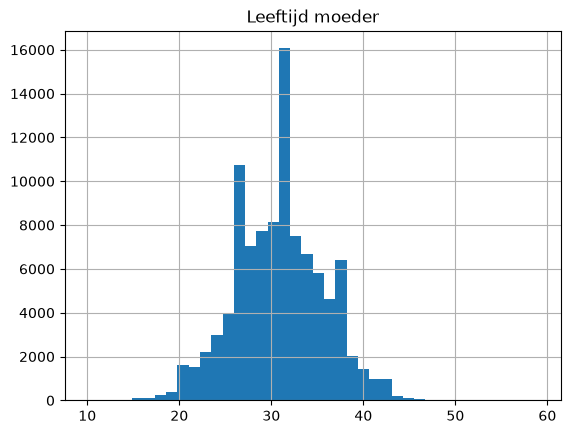

In [ ]:
df["lft"].hist(bins=40)
plt.title("Leeftijd moeder")
plt.show()

Observatie: De leeftijd zet ik om naar leeftijdsgroepen voor mijn deelvraag en voor privacy

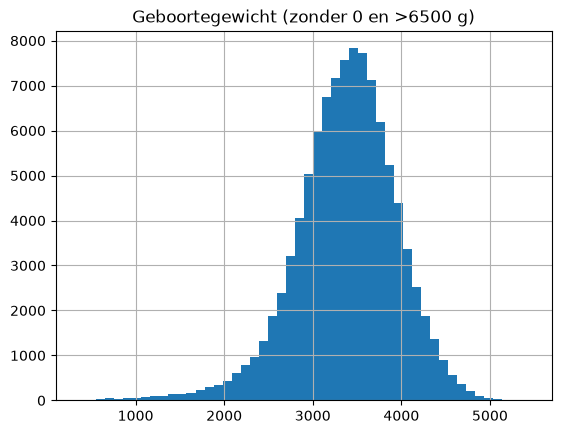

In [ ]:
gewicht = df[df["geboortegew"].between(1, 6500)]["geboortegew"]

gewicht.hist(bins=50)
plt.title("Geboortegewicht (zonder 0 en >6500 g)")
plt.show()

Observatie: Zonder registratiefouten heeft deze kolom een normale verdeling

In [ ]:
missend = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
missend[missend > 0]

congenafw8            100.00
sectio_ia             100.00
rookgedrag            100.00
congenafw1            100.00
congenafw6            100.00
congenafw5            100.00
etnic                 100.00
congenafw7            100.00
congenafw4            100.00
congenafw3             99.96
congenafw2             99.54
alcoholgebruik         96.19
drugsgebruik           95.14
amddd1ond               5.33
type_partus             3.13
ligging                 2.74
beginbaring_detail      2.62
beginbaring_basis       2.62
stedelijkheid           1.68
vrouwniveau             1.60
ses_percentiel          0.79
hoftiezer               0.75
par                     0.43
grav                    0.37
lft                     0.30
pc4                     0.24
gebplaats               0.19
apgar5                  0.14
geboortegew             0.12
gesl                    0.06
dtype: float64

Observatie: De 100% lege kolommen verwijder iklege waarden in de overige kolommen laat ik leeg

In [ ]:
onbekend_codes = {
    "provincie": 99,
    "gebplaats": 5,
    "beginbaring_basis": 9,
    "beginbaring_detail": 9,
    "verantw_zw": 9,
    "verantw_bb": 9,
    "verantw_eb": 9,
    "ovdr12": 9,
    "ligging": "UNK",
    "gesl": "UNK",
    "pediater": 4,
    "sterfte": 6,
}


In [ ]:
for kolom, code in onbekend_codes.items():
    onbekend = (df[kolom] == code).sum()
    missing = df[kolom].isna().sum()
    print(f"{kolom}: {onbekend} onbekend, {missing} missing")

provincie: 37613 onbekend, 0 missing
gebplaats: 67 onbekend, 189 missing
beginbaring_basis: 483 onbekend, 2624 missing
beginbaring_detail: 483 onbekend, 2624 missing
verantw_zw: 322 onbekend, 0 missing
verantw_bb: 3221 onbekend, 0 missing
verantw_eb: 256 onbekend, 0 missing
ovdr12: 3221 onbekend, 0 missing
ligging: 0 onbekend, 2742 missing
gesl: 0 onbekend, 65 missing
pediater: 24221 onbekend, 0 missing
sterfte: 10 onbekend, 0 missing


Observatie: oor provincie 99 maak ik de vlag provincie_bekend in plaats van 37,6% van de rijen te verwijderen.

BEPALEN WELKE MISSENDE WAARDEN TYPE IS HET(MAR, MCAR)

In [ ]:
df["lft_missing"] = df["lft"].isna()

print(df.groupby("provincie")["lft_missing"].mean().round(3))
print(df.groupby("jaar")["lft_missing"].mean().round(3))
print(df.groupby("gebplaats")["lft_missing"].mean().round(3))

provincie
1     0.005
2     0.003
3     0.003
4     0.003
5     0.004
6     0.002
7     0.004
8     0.002
9     0.003
10    0.004
11    0.002
12    0.001
99    0.003
Name: lft_missing, dtype: float64
jaar
2010    0.003
2011    0.003
2012    0.003
2013    0.003
2014    0.004
2015    0.004
2016    0.002
2017    0.003
2018    0.003
2019    0.003
2020    0.003
Name: lft_missing, dtype: float64
gebplaats
0.0    0.002
1.0    0.001
2.0    0.002
3.0    0.003
4.0    0.000
5.0    0.000
Name: lft_missing, dtype: float64


In [ ]:
df["ligging_missing"] = df["ligging"].isna() | (df["ligging"] == "UNK")

print(df.groupby("provincie")["ligging_missing"].mean().round(3))
print(df.groupby("jaar")["ligging_missing"].mean().round(3))
print(df.groupby("gebplaats")["ligging_missing"].mean().round(3))

provincie
1     0.026
2     0.026
3     0.026
4     0.028
5     0.026
6     0.027
7     0.021
8     0.028
9     0.030
10    0.030
11    0.029
12    0.032
99    0.027
Name: ligging_missing, dtype: float64
jaar
2010    0.030
2011    0.028
2012    0.026
2013    0.027
2014    0.026
2015    0.028
2016    0.027
2017    0.028
2018    0.029
2019    0.027
2020    0.027
Name: ligging_missing, dtype: float64
gebplaats
0.0    0.029
1.0    0.030
2.0    0.031
3.0    0.027
4.0    0.000
5.0    0.030
Name: ligging_missing, dtype: float64


In [ ]:
df["type_partus_missing"] = df["type_partus"].isna()

print(df.groupby("provincie")["type_partus_missing"].mean().round(3))
print(df.groupby("jaar")["type_partus_missing"].mean().round(3))
print(df.groupby("gebplaats")["type_partus_missing"].mean().round(3))

provincie
1     0.036
2     0.034
3     0.036
4     0.033
5     0.031
6     0.034
7     0.030
8     0.032
9     0.029
10    0.029
11    0.034
12    0.031
99    0.030
Name: type_partus_missing, dtype: float64
jaar
2010    0.032
2011    0.032
2012    0.031
2013    0.030
2014    0.028
2015    0.034
2016    0.030
2017    0.032
2018    0.031
2019    0.030
2020    0.035
Name: type_partus_missing, dtype: float64
gebplaats
0.0    0.032
1.0    0.025
2.0    0.033
3.0    0.031
4.0    0.000
5.0    0.015
Name: type_partus_missing, dtype: float64


In [ ]:
gewicht_missing = df["geboortegew"].isna()

print(gewicht_missing.groupby(df["provincie"]).mean().round(3))
print(gewicht_missing.groupby(df["jaar"]).mean().round(3))
print(gewicht_missing.groupby(df["gebplaats"]).mean().round(3))
print(gewicht_missing.groupby(df["sterfte"]).mean().round(3))

provincie
1     0.001
2     0.002
3     0.001
4     0.002
5     0.000
6     0.001
7     0.003
8     0.001
9     0.001
10    0.001
11    0.002
12    0.002
99    0.001
Name: geboortegew, dtype: float64
jaar
2010    0.001
2011    0.001
2012    0.001
2013    0.002
2014    0.002
2015    0.001
2016    0.001
2017    0.001
2018    0.001
2019    0.001
2020    0.001
Name: geboortegew, dtype: float64
gebplaats
0.0    0.001
1.0    0.001
2.0    0.001
3.0    0.001
4.0    0.000
5.0    0.000
Name: geboortegew, dtype: float64
sterfte
0    0.001
1    0.000
2    0.000
3    0.000
4    0.000
5    0.000
6    0.000
Name: geboortegew, dtype: float64


In [ ]:
df["beginbaring_basis_missing"] = df["beginbaring_basis"].isna() | df["beginbaring_basis"].isin([9, "9"])

print(df.groupby("provincie")["beginbaring_basis_missing"].mean().round(3))
print(df.groupby("jaar")["beginbaring_basis_missing"].mean().round(3))
print(df.groupby("gebplaats")["beginbaring_basis_missing"].mean().round(3))

provincie
1     0.026
2     0.033
3     0.032
4     0.034
5     0.035
6     0.030
7     0.026
8     0.031
9     0.032
10    0.030
11    0.027
12    0.035
99    0.031
Name: beginbaring_basis_missing, dtype: float64
jaar
2010    0.030
2011    0.032
2012    0.034
2013    0.032
2014    0.032
2015    0.030
2016    0.030
2017    0.031
2018    0.031
2019    0.029
2020    0.030
Name: beginbaring_basis_missing, dtype: float64
gebplaats
0.0    0.000
1.0    0.000
2.0    0.000
3.0    0.039
4.0    0.000
5.0    0.985
Name: beginbaring_basis_missing, dtype: float64


UNIVATIATE FEATURES (NUMERIEK)

Observatie: De missende waarden van deze kolommen zijn MCAR, dus ik zal ze leeg laten na de ETL

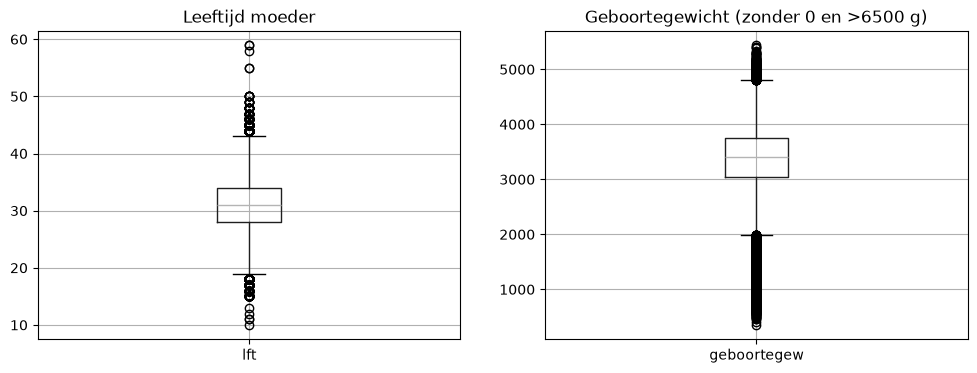

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.boxplot(column="lft", ax=axes[0])
axes[0].set_title("Leeftijd moeder")
df.loc[df["geboortegew"].between(1, 6500)].boxplot(column="geboortegew", ax=axes[1])
axes[1].set_title("Geboortegewicht (zonder 0 en >6500 g)")
plt.show()

Observatie: De uitschieters in leeftijd en gewicht behandel ik met de grenzen in de ETL

UNIVARIATE FEATURES(CATEGORISCH)

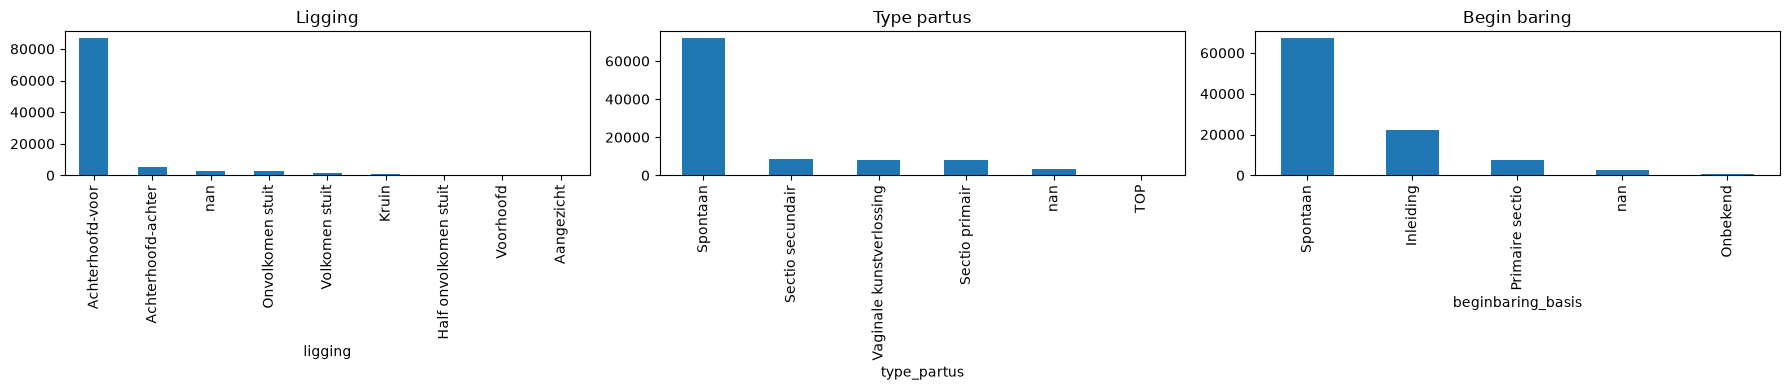

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
label("ligging", ligging_labels).value_counts(dropna=False).plot(kind="bar", ax=axes[0], title="Ligging")
label("type_partus", type_partus_labels).value_counts(dropna=False).plot(kind="bar", ax=axes[1], title="Type partus")
label("beginbaring_basis", beginbaring_labels).value_counts(dropna=False).plot(kind="bar", ax=axes[2], title="Begin baring")
plt.tight_layout()
plt.show()

CORRELATION ANALYSE

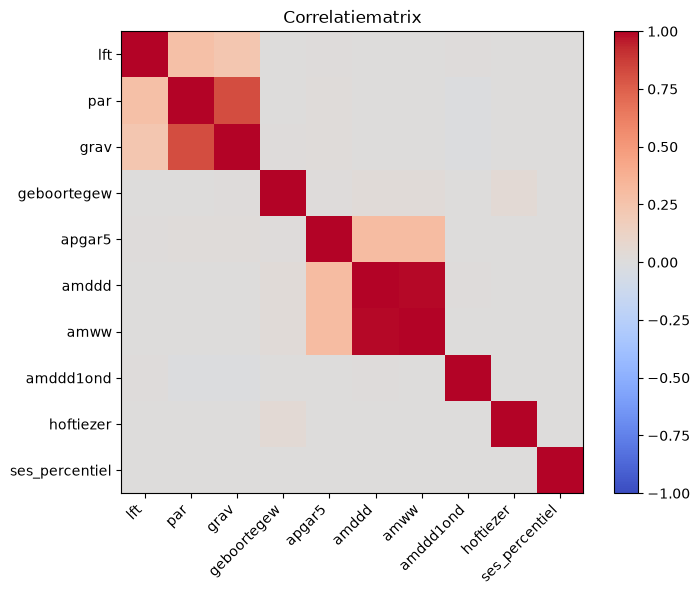

,lft,par,grav,geboortegew,apgar5,amddd,amww,amddd1ond,hoftiezer,ses_percentiel
lft,1.00,0.28,0.23,0.00,0.01,0.00,0.00,0.01,-0.00,0.0
par,0.28,1.00,0.82,0.00,0.02,-0.00,-0.00,-0.01,0.00,0.0
grav,0.23,0.82,1.00,0.01,0.02,-0.00,-0.00,-0.01,0.00,-0.0
geboortegew,0.00,0.00,0.01,1.00,0.01,0.03,0.03,-0.00,0.04,-0.0
apgar5,0.01,0.02,0.02,0.01,1.00,0.30,0.30,0.00,0.00,-0.0
amddd,0.00,-0.00,-0.00,0.03,0.30,1.00,0.99,0.01,-0.00,0.0
amww,0.00,-0.00,-0.00,0.03,0.30,0.99,1.00,0.00,-0.00,0.0
amddd1ond,0.01,-0.01,-0.01,-0.00,0.00,0.01,0.00,1.00,-0.00,-0.0
hoftiezer,-0.00,0.00,0.00,0.04,0.00,-0.00,-0.00,-0.00,1.00,-0.0
ses_percentiel,0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,1.0


In [ ]:
corr = df[numeriek].corr().round(2)
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(numeriek)), numeriek, rotation=45, ha="right")
plt.yticks(range(len(numeriek)), numeriek)
plt.title("Correlatiematrix")
plt.show()
corr

CONSISTENTIE

In [ ]:
thuis = label("gebplaats", gebplaats_labels) == "Thuis"
sectio = label("type_partus", type_partus_labels).isin(["Sectio primair", "Sectio secundair"])

print("Thuis + sectio:", (thuis & sectio).sum())

Thuis + sectio: 30


Thuis en sectio kan niet, alle sectios vinden plaats in de ziekenhuis, inconsistent. Zal in de etl corrigeerd worden

In [ ]:
gepland_sectio = label("beginbaring_basis", beginbaring_labels) == "Primaire sectio"
spontaan = label("type_partus", type_partus_labels) == "Spontaan"

print("Primaire sectio + spontaan:", (gepland_sectio & spontaan).sum())

Primaire sectio + spontaan: 0


EERSTE  VERKENNING DEELVRAAG

In [ ]:
pd.crosstab(label("beginbaring_basis", beginbaring_labels),
            label("type_partus", type_partus_labels), normalize="index").round(2)

type_partus,Sectio primair,Sectio secundair,Spontaan,TOP,Vaginale kunstverlossing
beginbaring_basis,,,,,
Inleiding,0.00,0.15,0.70,0.0,0.14
Onbekend,0.00,0.10,0.80,0.0,0.10
Primaire sectio,1.00,0.00,0.00,0.0,0.00
Spontaan,0.01,0.08,0.84,0.0,0.08


Observatie: Omdat primaire sectio altijd tot een sectio primair leidt, kan ik beginbaring_basis afleiden uit type_partus

In [ ]:
pd.crosstab(label("ligging", ligging_labels),
            label("type_partus", type_partus_labels), normalize="index").round(2)

type_partus,Sectio primair,Sectio secundair,Spontaan,TOP,Vaginale kunstverlossing
ligging,,,,,
Aangezicht,0.12,0.25,0.50,0.0,0.13
Achterhoofd-achter,0.10,0.21,0.56,0.0,0.13
Achterhoofd-voor,0.06,0.08,0.78,0.0,0.09
Half onvolkomen stuit,0.59,0.13,0.28,0.0,0.00
Kruin,0.11,0.20,0.52,0.0,0.16
Onvolkomen stuit,0.60,0.12,0.28,0.0,0.00
Volkomen stuit,0.59,0.13,0.28,0.0,0.00
Voorhoofd,0.06,0.19,0.66,0.0,0.10


Observatie: Voor deze vergelijking maak ik ligging_afwijkend en leeftijdsgroep, zodat ik dit per leeftijdsgroep kan uitsplitsen

In [ ]:

spontaan_start = label("beginbaring_basis", beginbaring_labels) == "Spontaan"
sectio_primair = label("type_partus", type_partus_labels) == "Sectio primair"
print("Spontaan begin + sectio primair:", (spontaan_start & sectio_primair).sum())

Spontaan begin + sectio primair: 542


In [ ]:
df["gebplaats"].value_counts(dropna=False).sort_index()

gebplaats
0.0    13428
1.0     2220
2.0    10420
3.0    73668
4.0        8
5.0       67
NaN      189
Name: count, dtype: int64

In [ ]:
(df["lft"] < 14).sum()

np.int64(5)

In [ ]:
jong = df[df["lft"] < 14]

print("moeders ouder dan 55:", (df["lft"] > 55).sum())

print("\nGebplaats jonger dan 14 jaar")
print(label("gebplaats", gebplaats_labels)[df["lft"] < 14].value_counts(dropna=False))

print("\nPariteit jonger dan 14 jaar")
print(jong["par"].value_counts(dropna=False).sort_index())

moeders ouder dan 55: 3

Gebplaats jonger dan 14 jaar
gebplaats
Ziekenhuis 2e lijn    4
Ziekenhuis 1e lijn    1
Name: count, dtype: int64

Pariteit jonger dan 14 jaar
par
0.0    2
1.0    1
2.0    1
3.0    1
Name: count, dtype: int64


In [ ]:
Observaties: Met leeftijden onder de 14 zal ik in de ETL een beslissing nemen

In [ ]:
print("par >= grav:", (df["par"] >= df["grav"]).sum())

par >= grav: 103


Observatie: je kan niet meer bevallingen hebben dan aantal keer die zwanger bent geweest. Lack of consitency, dit zal ik in de ETL corrigeren